# Used Car Prices in India: Exploratory Data Analysis

**Goal:** understand what affects the resale price of a used car.

**Data:** Kaggle *Used Car Prices* (sourced from Cars24). `Price` is in lakhs of rupees.

**Steps:** 1. Load the data → 2. Look at it → 3. Clean it → 4. Explore → 5. Conclusions

## 1. Load the data

First we import the libraries we need:
- `pandas` loads and handles tables (called *DataFrames*)
- `matplotlib` and `seaborn` draw charts

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

Now read the CSV file into a DataFrame called `df`. The `..` means "go up one folder", because this notebook is inside `notebooks/` and the data is in `data/`.

In [4]:
df = pd.read_csv("../data/train.csv")
df.shape

(5847, 14)

`shape` shows (rows, columns). Each row is one car listing.

## 2. Look at the data

`head()` shows the first 5 rows so we can see what the data looks like.

In [5]:
df.head()

,Unnamed: 0,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,New_Price,Price
0,1,Hyundai Creta 1.6 CRDi SX Option,Pune,2015,41000,Diesel,Manual,First,19.67 kmpl,1582 CC,126.2 bhp,5.0,NaN,12.50
1,2,Honda Jazz V,Chennai,2011,46000,Petrol,Manual,First,13 km/kg,1199 CC,88.7 bhp,5.0,8.61 Lakh,4.50
2,3,Maruti Ertiga VDI,Chennai,2012,87000,Diesel,Manual,First,20.77 kmpl,1248 CC,88.76 bhp,7.0,NaN,6.00
3,4,Audi A4 New 2.0 TDI Multitronic,Coimbatore,2013,40670,Diesel,Automatic,Second,15.2 kmpl,1968 CC,140.8 bhp,5.0,NaN,17.74
4,6,Nissan Micra Diesel XV,Jaipur,2013,86999,Diesel,Manual,First,23.08 kmpl,1461 CC,63.1 bhp,5.0,NaN,3.50


`info()` lists each column, how many values are filled in, and its data type. Look for columns that should be numbers but show as `object`/`str` (text).

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5847 entries, 0 to 5846
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         5847 non-null   int64  
 1   Name               5847 non-null   str    
 2   Location           5847 non-null   str    
 3   Year               5847 non-null   int64  
 4   Kilometers_Driven  5847 non-null   int64  
 5   Fuel_Type          5847 non-null   str    
 6   Transmission       5847 non-null   str    
 7   Owner_Type         5847 non-null   str    
 8   Mileage            5845 non-null   str    
 9   Engine             5811 non-null   str    
 10  Power              5811 non-null   str    
 11  Seats              5809 non-null   float64
 12  New_Price          815 non-null    str    
 13  Price              5847 non-null   float64
dtypes: float64(2), int64(3), str(9)
memory usage: 1.1 MB


`describe()` gives quick statistics (average, min, max) for the numeric columns.

In [7]:
df.describe()

,Unnamed: 0,Year,Kilometers_Driven,Seats,Price
count,5847.000000,5847.000000,5.847000e+03,5809.000000,5847.000000
mean,3013.181461,2013.448435,5.841013e+04,5.286452,9.653742
std,1736.398890,3.194949,9.237971e+04,0.806668,11.275966
min,1.000000,1998.000000,1.710000e+02,2.000000,0.440000
25%,1509.500000,2012.000000,3.346750e+04,5.000000,3.550000
50%,3015.000000,2014.000000,5.257600e+04,5.000000,5.750000
75%,4517.500000,2016.000000,7.249050e+04,5.000000,10.250000
max,6018.000000,2019.000000,6.500000e+06,10.000000,160.000000


Finally, count the missing values in each column.

In [8]:
df.isna().sum()

Unnamed: 0              0
Name                    0
Location                0
Year                    0
Kilometers_Driven       0
Fuel_Type               0
Transmission            0
Owner_Type              0
Mileage                 2
Engine                 36
Power                  36
Seats                  38
New_Price            5032
Price                   0
dtype: int64

## 3. Clean the data

What we found above:
- `Unnamed: 0` is just a row counter, and `New_Price` is 86% empty → **drop both**
- `Mileage`, `Engine` and `Power` are text with units ("19.67 kmpl") → **turn into numbers**
- `Name` mixes brand and model → **extract the brand**
- A few columns have blanks → **remove those rows**
- One car shows 6,500,000 km driven → **remove this outlier**

We work on a copy called `df_clean`, so the original `df` stays untouched.

### 3.1 Drop columns we don't need

In [9]:
df_clean = df.copy()
df_clean = df_clean.drop(columns=["Unnamed: 0", "New_Price"])
df_clean.shape

(5847, 12)

### 3.2 Turn text into numbers

`"19.67 kmpl"` is text, so we can't average it. We split on the space and keep only the first part (the number).

> Note: 3 CNG cars report mileage in `km/kg` instead of `kmpl`. The units are different but close, so we keep them as they are.

In [10]:
for col in ["Mileage", "Engine", "Power"]:
    df_clean[col] = pd.to_numeric(df_clean[col].str.split().str[0])

df_clean[["Mileage", "Engine", "Power"]].head()

,Mileage,Engine,Power
0,19.67,1582.0,126.20
1,13.00,1199.0,88.70
2,20.77,1248.0,88.76
3,15.20,1968.0,140.80
4,23.08,1461.0,63.10


### 3.3 Extract the brand

The brand is usually the first word of `Name`. Two fixes are needed:
- `Land Rover` has two words, so the first word alone gives just `Land`.
- `ISUZU` and `Isuzu` are the same brand with different capital letters, so we make all brands start with a capital. That turns `BMW` into `Bmw`, so we fix that one back.

In [11]:
df_clean["Brand"] = df_clean["Name"].str.split().str[0].str.title()
df_clean["Brand"] = df_clean["Brand"].replace({"Land": "Land Rover", "Bmw": "BMW"})
df_clean["Brand"].value_counts()

Brand
Maruti           1132
Hyundai          1057
Honda             607
Toyota            395
Mercedes-Benz     316
Volkswagen        314
Ford              295
Mahindra          269
BMW               267
Audi              235
Tata              181
Skoda             172
Renault           145
Chevrolet         120
Nissan             89
Land Rover         60
Jaguar             40
Mitsubishi         27
Mini               26
Fiat               26
Volvo              21
Porsche            16
Jeep               15
Datsun             13
Isuzu               3
Force               3
Ambassador          1
Bentley             1
Lamborghini         1
Name: count, dtype: int64

### 3.4 Remove rows with missing values

Only about 40 rows (under 1%) have blanks, so removing them costs almost nothing.

In [12]:
rows_before = len(df_clean)
df_clean = df_clean.dropna()
print(f"Removed {rows_before - len(df_clean)} rows, {len(df_clean)} left")

Removed 40 rows, 5807 left


### 3.5 Check the outlier

Look at the cars with the most kilometers driven.

In [13]:
df_clean.nlargest(3, "Kilometers_Driven")[["Name", "Year", "Kilometers_Driven", "Price"]]

,Name,Year,Kilometers_Driven,Price
2259,BMW X5 xDrive 30d M Sport,2017,6500000,65.0
326,Skoda Octavia Ambition Plus 2.0 TDI AT,2013,775000,7.5
1805,Volkswagen Vento Diesel Highline,2013,720000,5.9


The top car is a 2017 BMW X5 with **6,500,000 km**. That is impossible for a 2-year-old car (the data goes up to 2019), so it is a typing mistake. The next highest is 775,000 km, which is high but possible. We remove only the impossible one.

In [14]:
df_clean = df_clean[df_clean["Kilometers_Driven"] < 1_000_000]
df_clean["Kilometers_Driven"].describe()

count      5806.000000
mean      57239.541509
std       37910.104527
min         171.000000
25%       33286.000000
50%       52399.000000
75%       72443.750000
max      775000.000000
Name: Kilometers_Driven, dtype: float64

### 3.6 Check the result

No missing values should remain, and the number columns should now be numbers.

In [15]:
df_clean.info()

<class 'pandas.DataFrame'>
Index: 5806 entries, 0 to 5846
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Name               5806 non-null   str    
 1   Location           5806 non-null   str    
 2   Year               5806 non-null   int64  
 3   Kilometers_Driven  5806 non-null   int64  
 4   Fuel_Type          5806 non-null   str    
 5   Transmission       5806 non-null   str    
 6   Owner_Type         5806 non-null   str    
 7   Mileage            5806 non-null   float64
 8   Engine             5806 non-null   float64
 9   Power              5806 non-null   float64
 10  Seats              5806 non-null   float64
 11  Price              5806 non-null   float64
 12  Brand              5806 non-null   object 
dtypes: float64(5), int64(2), object(1), str(5)
memory usage: 928.5+ KB


In [16]:
df_clean.isna().sum().sum()

np.int64(0)

### 3.7 Save the clean data

We save it as a new file, `cars_clean.csv`, so Project 2 (price predictor) and Project 3 (dashboard) can start from clean data. The original `train.csv` is not changed.

In [17]:
df_clean.to_csv("../data/cars_clean.csv", index=False)
print(df_clean.shape)

(5806, 13)


## 4. Explore the data

Now the data is clean, we can ask questions and answer each one with a chart.

Each question follows the same pattern: **ask → calculate or plot → write what we learn**.

### 4.1 How are car prices spread out?

Before comparing anything, we need to know what a *normal* price looks like. `describe()` gives the numbers, and a **histogram** shows the shape. A histogram cuts the prices into bins (ranges) and counts how many cars fall in each bin.

In [18]:
df_clean["Price"].describe()

count    5806.000000
mean        9.663899
std        11.269610
min         0.440000
25%         3.590000
50%         5.750000
75%        10.247500
max       160.000000
Name: Price, dtype: float64

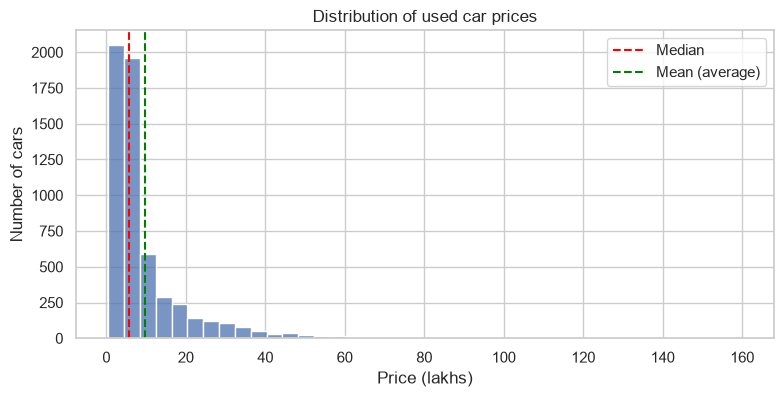

In [19]:
plt.figure(figsize=(9, 4))
sns.histplot(df_clean["Price"], bins=40)
plt.axvline(df_clean["Price"].median(), color="red", linestyle="--", label="Median")
plt.axvline(df_clean["Price"].mean(), color="green", linestyle="--", label="Mean (average)")
plt.title("Distribution of used car prices")
plt.xlabel("Price (lakhs)")
plt.ylabel("Number of cars")
plt.legend()
plt.show()

**What we learn:**
- The **median** (middle car) costs about **5.75 lakhs**, but the **mean** (average) is about **9.7 lakhs**.
- The average is higher because a few very expensive cars (up to 160 lakhs) pull it up. We call this a *right-skewed* distribution: a long tail on the right.
- About **74% of cars cost under 10 lakhs**, and only about 6% cost over 30 lakhs.
- The most expensive cars are real luxury cars (Range Rover, Lamborghini, Jaguar F-Type), so we keep them.

**Takeaway:** for this data, the **median** describes a typical car better than the mean.

### 4.2 Do older cars cost less?

We expect yes. Let's check. For each manufacturing year we take the **median price** (median, because we just saw that the mean is pulled up by luxury cars). `groupby("Year")` splits the cars into one group per year, then `.median()` works out each group's middle price.

In [20]:
price_by_year = df_clean.groupby("Year")["Price"].median()
price_by_year

Year
1998     0.530
1999     0.835
2000     1.100
2001     0.875
2002     1.000
2003     1.300
2004     1.400
2005     1.350
2006     1.800
2007     2.000
2008     2.600
2009     3.110
2010     3.000
2011     3.850
2012     4.500
2013     5.130
2014     5.750
2015     6.250
2016     7.000
2017     8.200
2018     8.875
2019    11.540
Name: Price, dtype: float64

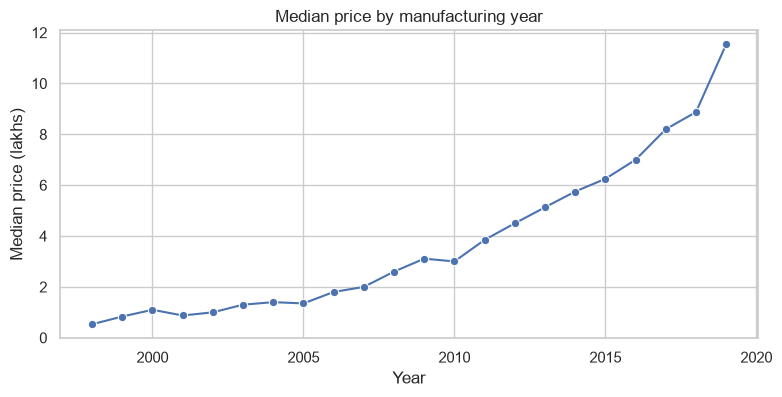

In [21]:
plt.figure(figsize=(9, 4))
sns.lineplot(x=price_by_year.index, y=price_by_year.values, marker="o")
plt.title("Median price by manufacturing year")
plt.xlabel("Year")
plt.ylabel("Median price (lakhs)")
plt.show()

**What we learn:**
- Yes. Prices rise steadily with the year: cars from the early 2000s have a median near **1 lakh**, 2014 cars about **5.75 lakhs**, and 2019 cars about **11.5 lakhs**.
- The line is not perfectly smooth for the oldest years, because there are only a few cars from each of those years (for example only 2 cars from 1999).

**Takeaway:** a car's age is a strong clue to its price, so `Year` will be an important input for the price predictor in Project 2.

### 4.3 Does diesel cost more than petrol?

We compare the price of each fuel type with a **box plot**. For each group it draws:
- a **box** covering the middle 50% of cars, with a line at the median
- **whiskers** reaching the normal range
- **dots** for unusually expensive cars

Only 2 cars are Electric, too few to compare, so we leave them out of the chart.

In [22]:
df_clean.groupby("Fuel_Type")["Price"].agg(["median", "mean", "count"]).round(2)

,median,mean,count
Fuel_Type,,,
Diesel,7.83,12.94,3151
Petrol,4.25,5.77,2655


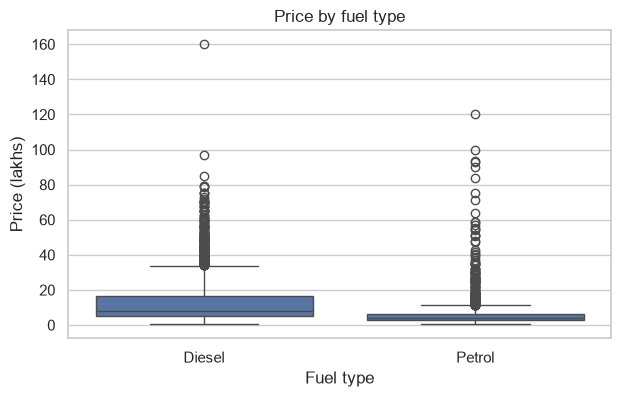

In [23]:
fuel = df_clean[df_clean["Fuel_Type"].isin(["Diesel", "Petrol"])]

plt.figure(figsize=(7, 4))
sns.boxplot(data=fuel, x="Fuel_Type", y="Price")
plt.title("Price by fuel type")
plt.xlabel("Fuel type")
plt.ylabel("Price (lakhs)")
plt.show()

**What we learn:**
- Diesel cars cost more: median **7.8 lakhs** vs **4.3 lakhs** for petrol.

**Be careful:** this does *not* prove diesel itself makes a car pricier. Diesel cars here also tend to have bigger engines (median about 1,600 cc vs 1,200 cc) and more power, and bigger cars cost more. Several things change together, so we can't say which one causes the price difference. This is the difference between **correlation** (they move together) and **causation** (one causes the other).

### 4.4 Which brands are the most expensive?

We take the median price of each brand. Brands with very few cars would give unreliable numbers (one expensive car could decide the whole brand), so we keep only brands with **at least 20 cars**.

In [24]:
brand_stats = df_clean.groupby("Brand")["Price"].agg(["median", "count"])
brand_stats = brand_stats[brand_stats["count"] >= 20].sort_values("median", ascending=False)
brand_stats

,median,count
Brand,,
Land Rover,35.000,57
Jaguar,31.900,40
Mini,24.285,26
Mercedes-Benz,24.230,316
Audi,23.500,235
BMW,21.330,261
Volvo,18.250,21
Toyota,11.000,393
Mitsubishi,9.950,27


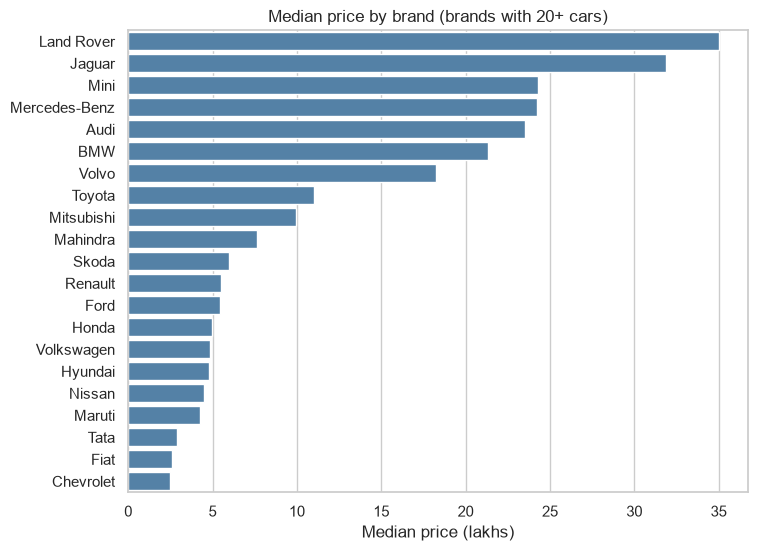

In [25]:
plt.figure(figsize=(8, 6))
sns.barplot(x=brand_stats["median"], y=brand_stats.index, color="steelblue")
plt.title("Median price by brand (brands with 20+ cars)")
plt.xlabel("Median price (lakhs)")
plt.ylabel("")
plt.show()

**What we learn:**
- The priciest brands are **Land Rover (35 lakhs), Jaguar (32), Mini, Mercedes-Benz, Audi and BMW (21 to 24)**.
- The cheapest are **Chevrolet (2.5), Fiat (2.6) and Tata (2.9)**, while the most common brands, **Maruti and Hyundai**, sit around 4 to 5 lakhs.

**Takeaway:** brand is a strong clue to price, so `Brand` is a good input for the predictor in Project 2.

### 4.5 Does driving more kilometers lower the price?

We expect yes. A **scatter plot** draws one dot per car: kilometers across, price up. `alpha=0.3` makes the dots see-through, so crowded areas look darker. We also group the cars into kilometer ranges and take each range's median price.

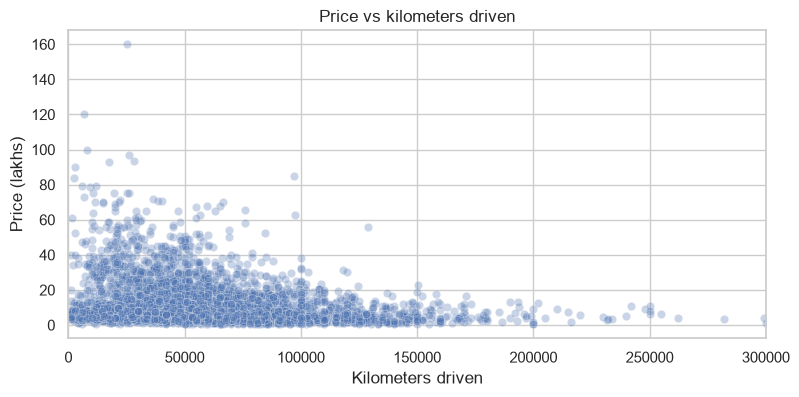

In [26]:
plt.figure(figsize=(9, 4))
sns.scatterplot(data=df_clean, x="Kilometers_Driven", y="Price", alpha=0.3)
plt.title("Price vs kilometers driven")
plt.xlabel("Kilometers driven")
plt.ylabel("Price (lakhs)")
plt.xlim(0, 300000)
plt.show()

In [27]:
km_ranges = pd.cut(df_clean["Kilometers_Driven"], [0, 25000, 50000, 75000, 100000, 150000, 1000000])
df_clean.groupby(km_ranges, observed=True)["Price"].median().round(2)

Kilometers_Driven
(0, 25000]           6.95
(25000, 50000]       6.25
(50000, 75000]       5.35
(75000, 100000]      4.88
(100000, 150000]     4.60
(150000, 1000000]    4.80
Name: Price, dtype: float64

**What we learn:**
- Yes, but only a little. The median price falls from about **7 lakhs** (under 25,000 km) to about **4.6 lakhs** (100,000 to 150,000 km).
- The correlation is only **-0.16**. A correlation runs from -1 to +1, and values near 0 mean a weak link. The dots form a cloud, not a clean line, because brand, year and engine matter a lot too.
- The x-axis stops at 300,000 km so the chart is readable. A few cars above that are not shown.

**Takeaway:** kilometers matter less than year and brand in this data.

### 4.6 Which city has the cheapest cars?

Same method as brands: the median price of each city, sorted.

In [28]:
city_stats = df_clean.groupby("Location")["Price"].agg(["median", "count"]).sort_values("median", ascending=False)
city_stats

,median,count
Location,,
Coimbatore,8.360,629
Bangalore,7.200,347
Kochi,6.820,637
Ahmedabad,6.000,217
Hyderabad,5.990,709
Mumbai,5.900,757
Delhi,5.700,535
Chennai,4.700,473
Pune,4.500,581


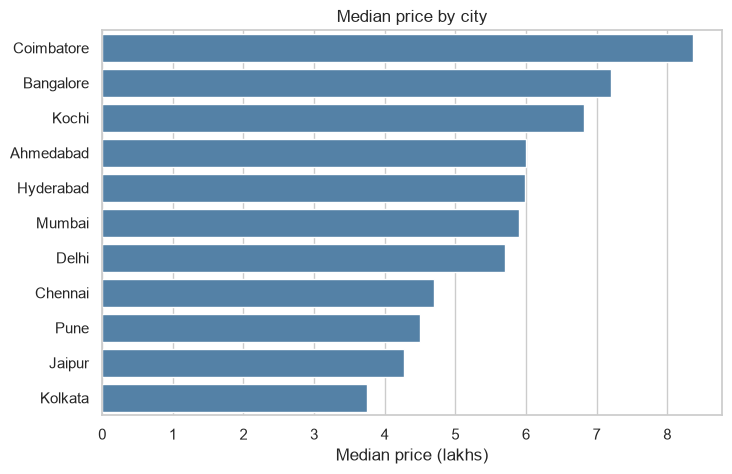

In [29]:
plt.figure(figsize=(8, 5))
sns.barplot(x=city_stats["median"], y=city_stats.index, color="steelblue")
plt.title("Median price by city")
plt.xlabel("Median price (lakhs)")
plt.ylabel("")
plt.show()

**What we learn:**
- **Coimbatore (8.4 lakhs)** and **Bangalore (7.2)** have the highest median prices. **Kolkata (3.8)**, **Jaipur (4.3)** and **Pune (4.5)** have the lowest.
- Every city has at least 200 cars, so the numbers are reasonably reliable.

**Be careful:** we can't tell *why* from this data. A city might simply sell more newer or more premium cars, not have higher prices for the same car. Comparing the same model across cities would be needed to say.

## 5. Conclusions

I cleaned and explored 5,806 used cars from India (from the original 5,847) to find out what affects resale price.

**Key findings**

1. **Most used cars are cheap, and a few luxury cars skew the average.** The median price is 5.75 lakhs but the mean is 9.7 lakhs, and 74% of cars cost under 10 lakhs. The median is the better measure of a typical car.
2. **Age is one of the strongest price signals.** Median price rises steadily with manufacturing year, from about 1 lakh for cars from the early 2000s to about 11.5 lakhs for 2019 cars.
3. **Brand matters a lot.** Land Rover (35 lakhs median), Jaguar, Mercedes-Benz, Audi and BMW sit at the top. Chevrolet, Fiat and Tata are at the bottom (under 3 lakhs).
4. **Diesel cars cost more than petrol cars** (7.8 vs 4.3 lakhs median), but this is likely linked to engine size, since diesel cars here have bigger engines (about 1,600 cc vs 1,200 cc). It does not show that diesel alone raises the price.
5. **Kilometers driven and city have a smaller effect.** The correlation between kilometers and price is only -0.16, and city medians range from 3.8 lakhs (Kolkata) to 8.4 lakhs (Coimbatore).

**Data cleaning**

- Removed 40 rows with missing values and 1 impossible row (a 2017 BMW X5 listed with 6,500,000 km).
- Dropped `New_Price` (86% missing) and a row-counter column.
- Converted Mileage, Engine and Power from text to numbers, and extracted a Brand column from the car name.

**Limitations**

- The data comes from one source (Cars24) and covers cars up to 2019, so it may not match today's market.
- These charts show links between things, not causes. Several factors (year, brand, engine size) change together.
- Three CNG cars report mileage in km/kg instead of km/l, and were kept as they are.

**Next steps**

- Project 2: build a model that predicts price from year, brand, kilometers, engine and other features.
- Project 3: turn these charts into an interactive dashboard.